# Mammograms denoising

## Context of this work
This work purpose is to experiment image quality improvement, applied on mammograms.

It links physical problem modeling, mathematics and ML, with a real problematic, and in this case, the biomedical field, which is critical.

## Data

### Dataset Exploration
We will use MIAS, a set of mammograms composed of 322 grayscale images with dimensions 1024x1024.
>Of course, these images do contain noise, but it is very light because the X-rays dose was high enough. Remember that our goal is to reduce the dose, therefore, denoising the images in consequence.

The dataset used in this work has been downloaded from Kaggle: https://www.kaggle.com/datasets/orvile/mias-dataset


In [1]:
import kagglehub
from pathlib import Path

# Download latest dataset version
ROOT = Path(kagglehub.dataset_download("orvile/mias-dataset"))


Using Colab cache for faster access to the 'mias-dataset' dataset.


In [ ]:
import torch
from torchvision.transforms.v2.functional import pil_to_tensor
import numpy as np
from PIL import Image

def invert_pixels(img):
    """uint8 image (NumPy or torch) -> inverted image in [0, 1], float."""
    return 1.0 - img / 255

def anscombe(z):
    """Apply anscombe transform"""
    return 2.0 * torch.sqrt(z + 3/8)

class PoissonNoise:
    def __init__(self, alphas):
        self.alphas = torch.tensor(alphas, dtype=torch.float32)

    def __call__(self, img):
        """Input must be a float, and must be inverted"""
        alpha = self.alphas[torch.randint(len(self.alphas), (1,))]
        k = torch.var(img) / torch.mean(img)

        # Convert pixel value to expected photons number, and simulate lower dose
        img = img / k
        img = img * alpha

        # Draw the detected photons
        img_noise = torch.poisson(img)

        # Anscombe transform on both noisy and clean photon maps
        noisy = anscombe(img_noise)
        clean = anscombe(img)

        return noisy, clean

class MIAS(torch.utils.data.Dataset):
    def __init__(self, root, names, alphas):
        self.img_dir = root / "MIAS"
        self.names = names
        self.noise = PoissonNoise(alphas)

    def __getitem__(self, idx):
        name = self.names[idx]
        t = pil_to_tensor(Image.open(self.img_dir / f"{name}.png"))   # uint8, shape (1, 1024, 
        t = invert_pixels(t)

        # Draft random patch
        p=128
        for _ in range(50): # Loop until a mostly breast patch is drafted
            i=torch.randint(0, 1024 - p + 1, (1,)).item()
            j=torch.randint(0, 1024 - p + 1, (1,)).item()

            if t[:, i:i+p, j:j+p].mean() < 0.8:
                break

        y = t[:, i:i+p, j:j+p] # Random patches

        x, y = self.noise(y) # x: noisy photon map, y: clean photon map


        return x, y         # Gives (x = noisy image patch, y = clean image patch)

    def __len__(self):
        return len(self.names)




Notice here that we separate each patients images, in order to not find the same patient in more than one set. This would add a bias to our model on the validation/test set, and compromise its rigorous evaluation.

In [3]:
names = sorted(p.stem for p in (ROOT / "MIAS").glob("mdb*.png")) 
patient = lambda name: (int(name[3:]) - 1) // 2          # mdb001, mdb002 -> 0 ; mdb003, mdb004 -> 1
patients = sorted({patient(n) for n in names})
g = torch.Generator().manual_seed(42)                    # seed
perm = [patients[i] for i in torch.randperm(len(patients), generator=g)] # Random permutations of patients
test_p, val_p, train_p = perm[:24], perm[24:48], perm[48:]

### Data augmentation (Noise simulation)
Since our goal is to denoise pictures of mammograms made with lower doses, we are going to simulate such mammograms, by adding noise.

To do so, we will first generate a Poisson noise. 
> The image contain pixel values which translates an intensity received by the detector rather a photon count. However, Poisson law makes sense if we interpretate pixel values as photon counts. This photon count interpretation will be necessary to quantify the dose reduction. 

We will then assume that a pixel value $z$ can be defined by a linear dependency between the real number of photons $\lambda$ and a factor $k$, hence we have $z= \lambda \cdot k$.

In order to get the actual value of that coefficient $k$, a trick is to use the pixel values mean and variance :
$$
\frac{\text{var}(z)}{\text{mean}(z)} = \frac{k^2 \cdot \text{var}(\lambda)}{k \cdot \text{mean} (\lambda)} = k
$$

This is what the original article did, and it works in principle, because their images pixels follows indeed the same distribution independently, therefore they have the same variance and mean.

> Important note: In the reference article, the data is measured from a modern digital detector. Our dataset is from 1994, before the development of digital mammograms, and are therefore scans. This implies more noise, and additionnaly, some anomalies that aren't desired (writings, files numbers...). The quality of the images isn't the best for our task, and we have to continue with it.

> Second note: because the processing is different between scans on films and digital, we will have to pre-process the data.


 Hence, we will continue and compute $k$ this way to estimate the photons number per pixel, as an approximation.

We can then simulate noise on the ground truth images by scaling down by a coefficient $\alpha$ the photon counts, within the poisson law:
$$
P(Z|\alpha \lambda) = \frac{(\alpha \lambda)^Z}{Z!} \cdot e^{-\alpha \lambda}
$$


In [4]:
import matplotlib.pyplot as plt

ROOT = Path(kagglehub.dataset_download("orvile/mias-dataset"))
alphas = [3.6]
train_names = [n for n in names if patient(n) in train_p]
val_names   = [n for n in names if patient(n) in val_p]
test_names  = [n for n in names if patient(n) in test_p]

train_set = MIAS(ROOT, train_names, alphas)
test_set = MIAS(ROOT, test_names, alphas)
val_set = MIAS(ROOT, val_names, alphas)

Using Colab cache for faster access to the 'mias-dataset' dataset.


Max: 16.04 | Min: 2.93 | Mean: 10.83  (Anscombe units)


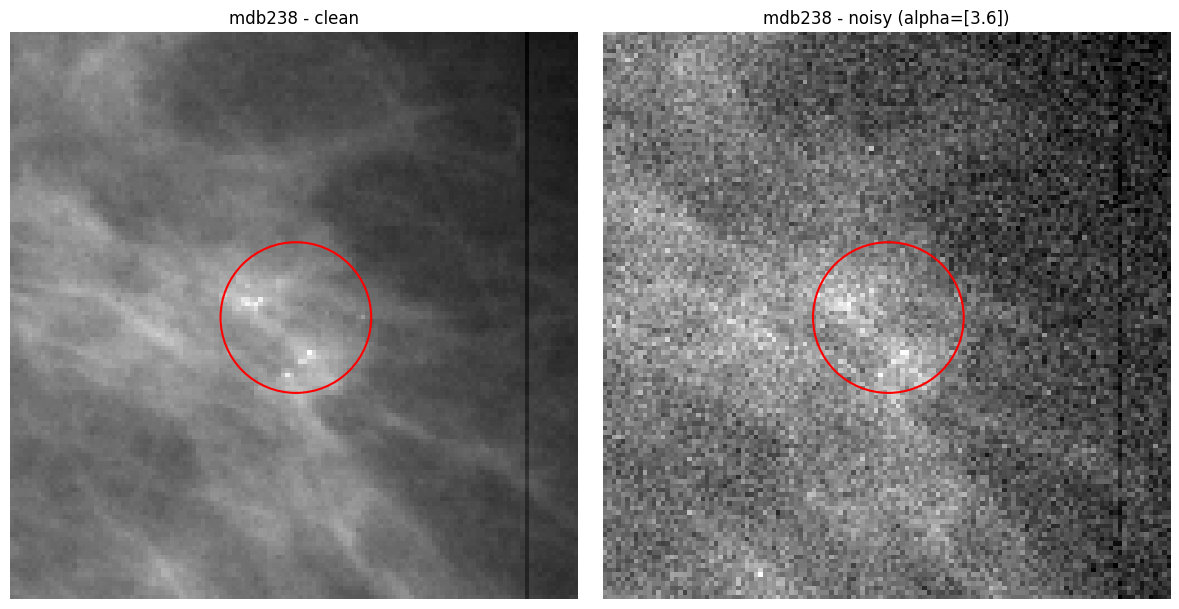

In [ ]:
# Visualization: zoom on a calcification
name, (row, col, rad) = "mdb238", (471, 522, 17)

s = 128                                              # zoom size, same as training patches

t = invert_pixels(pil_to_tensor(Image.open(ROOT / "MIAS" / f"{name}.png")))
r0 = min(max(row - s // 2, 0), 1024 - s)             # keep the square inside the image
c0 = min(max(col - s // 2, 0), 1024 - s)
patch = t[:, r0:r0+s, c0:c0+s]

torch.manual_seed(0)            # same noise every run
noisy, clean = train_set.noise(patch)   # same noise simulation as in training

vmin, vmax = clean.min().item(), clean.max().item()

print(f"Max: {vmax:.2f} | Min: {vmin:.2f} | Mean: {torch.mean(clean):.2f}  (Anscombe units)")

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(clean[0], cmap="gray_r", vmin=vmin, vmax=vmax)
ax[1].imshow(noisy[0], cmap="gray_r", vmin=vmin, vmax=vmax)
ax[0].set_title(f"{name} - Ground Truth")
ax[1].set_title(f"{name} - noisy  (alpha={alphas[0]})")
for a in ax:
    a.add_patch(plt.Circle((col - c0, row - r0), rad, fill=False, ec="red", lw=1.5))
    a.axis("off")
plt.tight_layout()
plt.show()

In [10]:
train_loader = torch.utils.data.DataLoader(train_set, batch_size=16, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=16, shuffle=False)
val_loader = torch.utils.data.DataLoader(val_set, batch_size=16, shuffle=False)

## Model Architecture
We will define the following ResNet:

![ResNet](figures/ResNet.png)

It is composed, sequentially of :
- **One input layer**: take one 128x128 patch from a given image, and output 64 feature maps, produced by 3x3 kernels followed with a ReLU
- **x15 Residual blocks**: 
    - Each containing three 64 kernels, 3x3 conv layers, followed by Batch Norm and ReLU
    - One skip connection, feeding the block input to the output in an element wise sum
- **One output layer**: take one 1024x1024 input image and return one feature map, produced by a 3x3 kernel.

The convolutions are padded, in order to keep the same dimensions with the original input, for each feature maps. This is in order to obtain the same image resolution as output.

In [25]:
import torch
class ResNet(torch.nn.Module):
    def __init__(self, num_blocks=15):
        super(ResNet, self).__init__()

        self.block_in = torch.nn.Sequential(
            # Input: 128x128 patch, 1 feature (grayscale)
            torch.nn.Conv2d(in_channels=1, out_channels=64, kernel_size=(3,3), padding=(1,1)),  # If unpadded -> 1022x1022 output
            torch.nn.ReLU()
        )

        self.num_blocks = num_blocks
        self.block_resnet = torch.nn.ModuleList(
            [torch.nn.Sequential(
                torch.nn.Conv2d(in_channels=64, out_channels=64, kernel_size=(3,3), padding=(1,1)),
                torch.nn.BatchNorm2d(num_features=64),
                torch.nn.ReLU(),
    
                torch.nn.Conv2d(in_channels=64, out_channels=64, kernel_size=(3,3), padding=(1,1)),
                torch.nn.BatchNorm2d(num_features=64),
                torch.nn.ReLU(),
    
                torch.nn.Conv2d(in_channels=64, out_channels=64, kernel_size=(3,3), padding=(1,1)),
                torch.nn.BatchNorm2d(num_features=64),
                torch.nn.ReLU(),
            ) for i in range(num_blocks)]
            )

        self.block_out = torch.nn.Conv2d(in_channels=64, out_channels=1, kernel_size=(3,3), padding=(1,1))

    def forward(self, x):
        x_ = self.block_in(x)

        for l in self.block_resnet:
            x_ = l(x_) + x_

        y = self.block_out(x_) # Noise predicted

        return x - y    # Return noise free image

## Training

In [12]:
# Device agnostic code
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [ ]:
# making sure we have a checkpoints folder
import os
os.makedirs("checkpoints", exist_ok=True)
ckpt_dir = "checkpoints"

# ---Uncomment if using colab ---
# from google.colab import drive
# import os

# drive.mount("/content/drive")                                   # sign-in prompt appears

# ckpt_dir = "/content/drive/MyDrive/mias_checkpoints_patchk"
# os.makedirs(ckpt_dir, exist_ok=True)
# print(os.listdir(ckpt_dir))                                     # empty list = new folder ready
# !pip install torchmetrics # If using colab

An obvious solution to compute the loss would be to use the MSE ($MSE = \frac{1}{n}\sum_i (y_{pred} - y)^2$), since we're comparing numerical values.

But human perception isn't maximized by minimization of the MSE. To take it into consideration following the article from Zhao et al. (see Sources in README), we will compute the SSIM (Structural Similarity Index).
This metric computes for each local neighborhood between a prediction patch $x$ and its label patch $y$, three pixel characteristics:
- the brightness (mean $\mu x, \mu y$)
- the contrast (std: $\sigma x, \sigma y$)
- the pattern variation: $\sigma_{xy}$ 

We can then compare three metrics:
- luminance  $l(x,y) = (2·μx·μy + C1) / (μx² + μy² + C1)$
- contrast   $c(x,y) = (2·σx·σy + C2) / (σx² + σy² + C2)$
- structure  $s(x,y) = (σxy + C3)     / (σx·σy + C3)$

We then have the SSIM:
$$
S(x,y) = f(l(x,y),c(x,y),s(x,y)) = (2·μx·μy + C1)(2·σxy + C2) / ((μx² + μy² + C1)(σx² + σy² + C2))
$$

In [14]:
# For SSIM loss
from torchmetrics.functional.image import structural_similarity_index_measure as ssim_fn

torch.manual_seed(0)
batches = [(x, y) for x, y in train_loader]
# Fixed SSIM data range, the same for every batch
DATA_RANGE = max(y.max().item() for _, y in batches) - min(y.min().item() for _, y in batches)

# Weight that makes w*(1-SSIM) about the same size as MSE (the paper found 10 on its data)
mse_ref  = sum(torch.nn.functional.mse_loss(x, y).item() for x, y in batches) / len(batches)
ssim_ref = sum((1 - ssim_fn(x, y, data_range=DATA_RANGE)).item() for x, y in batches) / len(batches)
W_SSIM = mse_ref / ssim_ref
print(f"DATA_RANGE={DATA_RANGE:.2f}  MSE={mse_ref:.4f}  1-SSIM={ssim_ref:.4f}  W_SSIM={W_SSIM:.2f}")

DATA_RANGE=90.87  MSE=0.9894  1-SSIM=0.1092  W_SSIM=9.06


In [ ]:
model = ResNet(num_blocks=15)
model.to(device)

def loss_fn(y_pred, y):
    mse = torch.nn.functional.mse_loss(y_pred, y)       # MSE alone was poor without SSIM
    s   = 1 - ssim_fn(y_pred, y, data_range=DATA_RANGE)
    return mse + W_SSIM * s, mse.item(), s.item()



optimizer = torch.optim.Adam(model.parameters(), lr=1.e-4)
history = {"train_loss": [], "val_loss": []}

epochs = 100
for epoch in range(epochs):
    epoch_train_loss = 0.0
    epoch_val_loss = 0.0

    # Training loop
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()

        # Forward pass
        y_pred = model(x)

        # Loss
        train_loss, train_mse, train_s = loss_fn(y_pred, y)
        train_loss.backward()

        # Step
        optimizer.step()

        epoch_train_loss += train_loss.item()

    history['train_loss'].append(epoch_train_loss / len(train_loader))

    # Evaluation loop
    model.eval()
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)

            y_pred = model(x)

            # Loss computing
            val_loss, val_mse, val_s = loss_fn(y_pred, y)

            epoch_val_loss += val_loss.item()

    history['val_loss'].append(epoch_val_loss / len(val_loader))

    checkpoint = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'history': history,
    }

    print(f"Epoch: {epoch} | Train loss: {history['train_loss'][-1]:.4f} | Val loss: {history['val_loss'][-1]:.4f}")

    if (epoch+1) % 5 == 0:
        torch.save(checkpoint, f'{ckpt_dir}/v7-{epoch}-alpha-{alphas[0]}-loss-{history['val_loss'][-1]:.2f}.pt')
        print("> Checkpoint saved")        

## Evaluation and Results

The model has been trained with a $\alpha = 3.6$, an arbitrary value to represent a decent noise. Due to a lack of informations on the dataset, the computation of $k$ in order to compute $\lambda$ isn't perfect. Which lead to an $\alpha$ different from the expected one.

In order to evaluate its performances, we computed the standard metrics in denoising tasks: the PSNR (Peak Signal-to-Noise Ratio) to evaluate the quality of the output image. It is defined by:

$$
\text{PSNR} = 10 \cdot \log_{10}\left(\frac{\text{MAX}^2}{\text{MSE}}\right)
$$
where:
- $MAX$: largest possible pixel value
- $MSE$ is the mean squared error between the generated image and the original

We obtained an average PSNR of 50.42 on the test set (while noisy image had an average of 39.19 dB), the model improves the PSNR by 11.23 dB. By the same way, we obtained a SSIM of 0.990 (0.891 for noisy images), which shows a gain of 0.099.

We can deduce our model is efficient to denoise a given image, with this noise.

### Limitations
the PSNR and SSIM are averages over all pixels. Which means that a denoising method that smooth the image and erase meaningful details won't be penalized as we would like to. To show visually show the limitation of these metrics, an example of denoising on microcalcifications is presented in the cell below.

In [ ]:
CKPT = "checkpoints/epoch95-alpha3.6-loss0.16.pt"
model = ResNet(num_blocks=15).to(device)
model.load_state_dict(torch.load(CKPT, map_location=device)["model_state_dict"])
model.eval()

def psnr(img_ref, img):
    """Batch (B, 1, H, W) in Anscombe units -> PSNR per image (dB), peak = DATA_RANGE."""
    mse = torch.mean((img - img_ref) ** 2, dim=(1, 2, 3))
    return 10 * torch.log10(DATA_RANGE ** 2 / mse)

def ssim(img_ref, img):
    """Batch -> SSIM per image, in [0, 1]. 1 = same structure."""
    return ssim_fn(img, img_ref, data_range=DATA_RANGE, reduction="none")

@torch.no_grad()
def evaluate(model, dataset, rounds=8):
    """
    Returns one row per patch: [PSNR noisy, PSNR denoised, SSIM noisy, SSIM denoised].
    """
    loader = torch.utils.data.DataLoader(dataset, batch_size=16, shuffle=False)
    rows = []
    with torch.random.fork_rng():          # the seed only applies inside this block
        torch.manual_seed(0)
        for _ in range(rounds):
            for noisy, clean in loader:
                den = model(noisy.to(device)).cpu()
                rows.append(torch.stack([psnr(clean, noisy), psnr(clean, den),
                                         ssim(clean, noisy), ssim(clean, den)], dim=1))
    return torch.cat(rows).numpy()

r = evaluate(model, test_set)

print(f"{len(r)} test patches, alpha = {alphas[0]}")
print(f"PSNR  noisy {r[:,0].mean():.2f} dB  ->  denoised {r[:,1].mean():.2f} dB   (gain {(r[:,1] - r[:,0]).mean():+.2f} dB)")
print(f"SSIM  noisy {r[:,2].mean():.3f}     ->  denoised {r[:,3].mean():.3f}      (gain {(r[:,3] - r[:,2]).mean():+.3f})")


384 test patches, alpha = 3.6
PSNR  noisy 39.19 dB  ->  denoised 50.42 dB   (gain +11.23 dB)
SSIM  noisy 0.891     ->  denoised 0.990      (gain +0.099)


> As the article we are following does, for a better visibility, we display the results on a small area of a mammogram, containing microcalcifications.

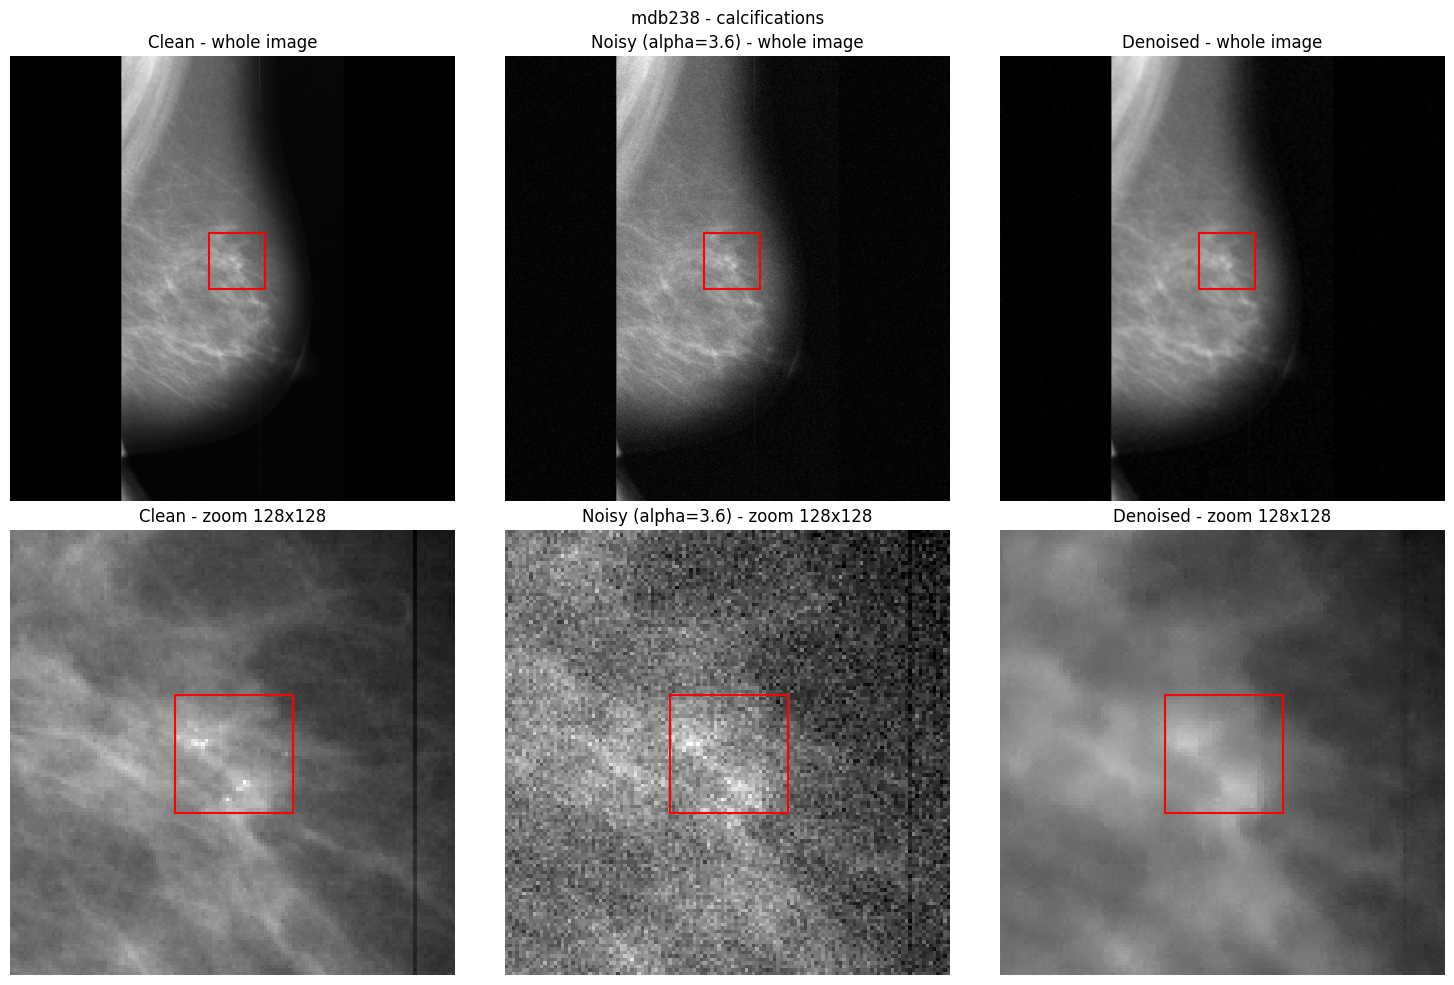

In [ ]:
# ---------- settings ----------
CKPT = "checkpoints/epoch95-alpha3.6-loss0.16.pt"
name, (row, col, rad) = "mdb238", (471, 522, 17)     # calcification centre (row, col) and radius
s = 128                                              # zoom size
# ------------------------------

net = ResNet(num_blocks=15).to(device)
net.load_state_dict(torch.load(CKPT, map_location=device)["model_state_dict"])
net.eval()

t = invert_pixels(pil_to_tensor(Image.open(ROOT / "MIAS" / f"{name}.png")))
r0 = min(max(row - s // 2, 0), 1024 - s)             # keep the zoom inside the image
c0 = min(max(col - s // 2, 0), 1024 - s)

# Noise the whole image, with k from the zoom area -> same noise level as the training patches
area = t[:, r0:r0+s, c0:c0+s]
photons = alphas[0] * t / (torch.var(area) / torch.mean(area))
torch.manual_seed(0)
noisy, clean = anscombe(torch.poisson(photons)), anscombe(photons)

with torch.no_grad():
    den = net(noisy[None].to(device))[0].cpu()

zoom = lambda img: img[0, r0:r0+s, c0:c0+s]
vmin, vmax   = clean.min().item(), clean.max().item()               # contrast, whole image
zmin, zmax   = zoom(clean).min().item(), zoom(clean).max().item()   # contrast, zoom

fig, ax = plt.subplots(2, 3, figsize=(15, 10))
for j, (img, title) in enumerate([(clean, "Clean"), (noisy, f"Noisy (alpha={alphas[0]})"), (den, "Denoised")]):
    ax[0, j].imshow(img[0], cmap="gray_r", vmin=vmin, vmax=vmax)
    ax[0, j].add_patch(plt.Rectangle((c0, r0), s, s, fill=False, ec="red", lw=1.5))
    ax[0, j].set_title(f"{title} - whole image")

    ax[1, j].imshow(zoom(img), cmap="gray_r", vmin=zmin, vmax=zmax, interpolation="nearest")
    ax[1, j].add_patch(plt.Rectangle((col - c0 - rad, row - r0 - rad), 2 * rad, 2 * rad, fill=False, ec="red", lw=1.5))
    ax[1, j].set_title(f"{title} - zoom {s}x{s}")
for a in ax.ravel():
    a.axis("off")
plt.suptitle(f"{name} - calcifications")
plt.tight_layout()
plt.show()

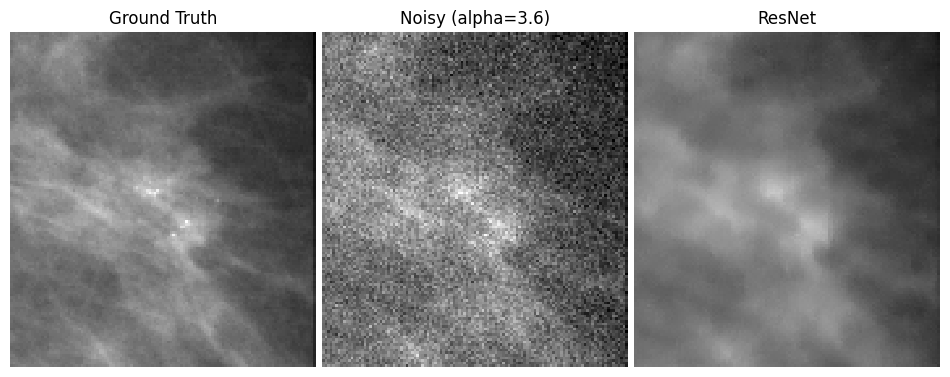

In [ ]:
# ---------- settings ----------
CKPT = "checkpoints/epoch95-alpha3.6-loss0.16.pt"
name, (row, col) = "mdb238", (471, 522)              # calcification centre (row, col)
s = 128                                              # zoom size
# ------------------------------

net = ResNet(num_blocks=15).to(device)
net.load_state_dict(torch.load(CKPT, map_location=device)["model_state_dict"])
net.eval()

t = invert_pixels(pil_to_tensor(Image.open(ROOT / "MIAS" / f"{name}.png")))
r0 = min(max(row - s // 2, 0), 1024 - s)             # keep the zoom inside the image
c0 = min(max(col - s // 2, 0), 1024 - s)

# Noise the whole image, with k from the zoom area -> same noise level as the training patches
area = t[:, r0:r0+s, c0:c0+s]
photons = alphas[0] * t / (torch.var(area) / torch.mean(area))
torch.manual_seed(0)
noisy, clean = anscombe(torch.poisson(photons)), anscombe(photons)

with torch.no_grad():
    den = net(noisy[None].to(device))[0].cpu()

crop = 11                                            # pixels removed on the right (scan artifact)
zoom = lambda img: img[0, r0:r0+s, c0:c0+s-crop]
zmin, zmax = zoom(clean).min().item(), zoom(clean).max().item()     # same contrast for the 3 panels

fig, ax = plt.subplots(1, 3, figsize=(12, 5))
for a, (img, title) in zip(ax, [(clean, "Ground Truth"), (noisy, f"Noisy (alpha={alphas[0]})"), (den, "ResNet")]):
    a.imshow(zoom(img), cmap="gray_r", vmin=zmin, vmax=zmax, interpolation="nearest")
    a.set_title(title)
    a.axis("off")
plt.subplots_adjust(wspace=0.02)                     # horizontal gap between panels (fraction of a panel's width)
plt.show()

### Comparing with another method: BM3D
BM3D (Block Matching and 3D Filtering) is a deterministic algorithm commonly used for noise reduction. It is a collaborative filtering process.

See more info: https://webpages.tuni.fi/foi/GCF-BM3D/BM3D_TIP_2007.pdf

In [18]:
# For colab
!pip install bm3d

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 862.0/862.0 kB 15.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [bm3d]


In [19]:
import bm3d

# BM3D evaluation on the dataset
def denoise_bm3d(noisy):
    """
    input: batch (B, 1, H, W) in Anscombe units.
    output: BM3D denoised image
    *sigma_psd = 1 because the Anscombe transform makes the noise std ≈ 1.
    """
    out = [bm3d.bm3d(x[0].numpy(), sigma_psd=1.0) for x in noisy]
    return torch.from_numpy(np.stack(out)).float()[:, None]

def evaluate(methods, dataset, rounds=8):
    """
    Returns {name: array (n_patches, 2)} with [PSNR, SSIM] per patch, 'Noisy' included.
    """
    loader = torch.utils.data.DataLoader(dataset, batch_size=16, shuffle=False)
    res = {"Noisy": [], **{name: [] for name in methods}}
    with torch.random.fork_rng():
        torch.manual_seed(0)
        for _ in range(rounds):
            for noisy, clean in loader:
                res["Noisy"].append(torch.stack([psnr(clean, noisy), ssim(clean, noisy)], dim=1))
                for name, denoise in methods.items():
                    den = denoise(noisy)
                    res[name].append(torch.stack([psnr(clean, den), ssim(clean, den)], dim=1))
    return {name: torch.cat(v).numpy() for name, v in res.items()}

methods = {
    "BM3D":   denoise_bm3d,
    "ResNet": lambda x: model(x.to(device)).cpu(),
}

with torch.no_grad():
    res = evaluate(methods, test_set)

print(f"{len(res['Noisy'])} test patches, alpha = {alphas[0]}\n")
print(f"{'Method':8s} {'PSNR (dB)':>10s} {'gain':>8s} {'SSIM':>7s}")
for name, v in res.items():
    gain = (v[:, 0] - res["Noisy"][:, 0]).mean()
    print(f"{name:8s} {v[:,0].mean():10.2f} {gain:+8.2f} {v[:,1].mean():7.3f}")


384 test patches, alpha = 3.6

Method    PSNR (dB)     gain    SSIM
Noisy         39.19    +0.00   0.891
BM3D          51.40   +12.21   0.991
ResNet        50.42   +11.23   0.990


On this test, both methods were scored on exactly the same patches and noise, so they can be compared patch by patch. 

We observe the following output: 
````
Method    PSNR (dB)     gain    SSIM
Noisy         39.19    +0.00   0.891
BM3D          51.40   +12.21   0.991
ResNet        50.42   +11.23   0.990
````
BM3D outperforms the ResNet by about 1dB.